In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import sys
import os

# ==========================================
# 1. 配置与加载
# ==========================================
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

# 变量映射 (基于你确认过的真实列名)
col_map = {
    'albedo': 'Albedo',             # 目标
    'strd': 'Strd',                 # 长波辐射
    'ssrd': 'Ssrd',                 # 短波辐射
    't2m': 'T2m',                   # 2m气温
    'u10': 'U10',                   # 纬向风 (西风分量)
    'v10': 'V10',                   # 经向风 (南风分量)
    'altitude_last_valid': 'Alt',   # 海拔
    'longitude': 'Lon'              # 经度
}

print(f"正在读取文件: {file_path} ...")
if not os.path.exists(file_path):
    print("❌ 文件不存在")
    sys.exit(1)

try:
    df = pd.read_csv(file_path, usecols=list(col_map.keys()))
    df.rename(columns=col_map, inplace=True)
    df.dropna(inplace=True)
    print(f"数据加载成功。有效样本数: {len(df):,}")
except Exception as e:
    print(f"❌ 读取错误: {e}")
    sys.exit(1)

# 定义要分析的物理变量列表
phys_vars = ['Strd', 'Ssrd', 'T2m', 'U10', 'V10']

# ==========================================
# 第一步：海拔分组分析 (Inland vs Margin)
# ==========================================
print("\n" + "="*80)
print("📊 STEP 1: 海拔分组分析 (Elevation Regimes)")
print("   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制")
print("="*80)

regions = {
    'Inland (>1500m)': df[df['Alt'] > 1500],
    'Margin (<1500m)': df[df['Alt'] <= 1500]
}

for name, subset in regions.items():
    print(f"\n📍 [{name}] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10} | {'Interpretation Hint'}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        
        # 简单的自动解读标记
        hint = ""
        if "Margin" in name and var == "Strd" and r < -0.3: hint = "🔥 Melt driven (Cloud/Warmth)"
        if "Margin" in name and var == "Ssrd" and r < -0.3: hint = "☀️ Melt driven (Sun)"
        if "Inland" in name and var == "Strd" and r < 0:    hint = "❄️ Radiative Cooling?"
        
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}  | {hint}")

# ==========================================
# 第二步：内陆东西细分 (Inland West vs East)
# ==========================================
print("\n" + "="*80)
print("🧭 STEP 2: 内陆东西部细分 (Inland West vs East)")
print("   仅分析海拔 > 1500m 区域，以 -42°W 为界")
print("="*80)

# 只取内陆
df_inland = df[df['Alt'] > 1500].copy()
# 划分东西
df_inland['Sector'] = df_inland['Lon'].apply(lambda x: 'West' if x < -42 else 'East')

sectors = ['West', 'East']

for sector in sectors:
    subset = df_inland[df_inland['Sector'] == sector]
    print(f"\n📍 [{sector.upper()} INLAND] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}")

print("\n" + "="*80)
print("✅ 分析完成。请复制上方结果。")

In [ ]:
 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

==========================================================================================
🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)

In [6]:
import pandas as pd
import glob
import os
import sys
from scipy.stats import pearsonr

# ==========================================
# 1. 配置
# ==========================================
folder_path = r"C:\Users\11823\era5land\202209202402"
file_pattern = "*prediction.csv"

# 只需要读取核心变量
use_cols = [
    'albedo', 't2m', 'u10',     # 核心分析变量
    'altitude_last_valid',      # 用于海拔切片
    'longitude', 'latitude'     # 用于区域切片
]

col_rename = {
    'altitude_last_valid': 'Alt',
    'longitude': 'Lon',
    'latitude': 'Lat',
    'albedo': 'Albedo',
    't2m': 'T2m',
    'u10': 'U10'
}

# ==========================================
# 2. 高效读取数据 (一次性读取到内存)
# ==========================================
print(f"🚀 正在加载 450 个文件到内存 (优化模式)...")
all_files = glob.glob(os.path.join(folder_path, file_pattern))

data_buffer = []
for i, f in enumerate(all_files):
    try:
        df_chunk = pd.read_csv(f, usecols=use_cols)
        df_chunk.rename(columns=col_rename, inplace=True)
        df_chunk.dropna(inplace=True)
        data_buffer.append(df_chunk)
        
        if (i+1) % 50 == 0:
            print(f"  已加载 {i+1}/{len(all_files)} 个文件...")
    except Exception as e:
        pass

if not data_buffer:
    print("❌ 没有读取到数据！")
    sys.exit(1)

print("📥 正在合并全量数据...")
df_all = pd.concat(data_buffer, ignore_index=True)
del data_buffer # 释放内存
print(f"✅ 全量数据就绪: {len(df_all):,} 行")

# ==========================================
# 3. 定义实验参数网格
# ==========================================

# A. 海拔切片 (3层)
elevation_bins = [
    (2000, 9000, "High Inland (>2000m)"),  # 核心内陆
    (1000, 2000, "Transition (1-2km)"),    # 过渡带
    (0,    1000, "Low Margin (<1000m)")    # 边缘消融区
]

# B. 经度分界线测试 (3组)
# 我们关注 "East"，所以 Lon > threshold
longitude_splits = [-44, -42, -40] 

# ==========================================
# 4. 执行网格分析
# ==========================================
print("\n" + "="*90)
print("🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证")
print("   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)")
print("="*90)

# 表头
header = f"{'Split(Lon)':<12} | {'Elevation Zone':<20} | {'N (Samples)':<12} | {'U10 vs T2m':<15} | {'U10 vs Albedo':<15} | {'Mechanism?'}"
print(header)
print("-" * 100)

for split_lon in longitude_splits:
    print(f"--- Testing Divider: {split_lon}°W ---")
    
    # 筛选出该分界线以东的所有数据
    df_east_all = df_all[df_all['Lon'] >= split_lon]
    
    for (min_h, max_h, label) in elevation_bins:
        # 筛选海拔
        subset = df_east_all[(df_east_all['Alt'] >= min_h) & (df_east_all['Alt'] < max_h)]
        n = len(subset)
        
        if n < 1000:
            print(f"{split_lon:<12} | {label:<20} | {n:<12} | (样本不足)")
            continue
            
        # 1. 计算 U10 vs T2m (验证焚风热效应)
        r_heat, p_heat = pearsonr(subset['U10'], subset['T2m'])
        
        # 2. 计算 U10 vs Albedo (验证反照率响应)
        r_alb, p_alb = pearsonr(subset['U10'], subset['Albedo'])
        
        # 3. 自动诊断机制
        mech = ""
        # 焚风特征: 风越大越热(r_heat>0)，且越暗(r_alb<0)
        if r_heat > 0.1 and r_alb < -0.1:
            mech = "🔥 Foehn Melt (Darkening)"
        # 堆积特征: 风越大越冷/不变，且越亮(r_alb>0)
        elif r_alb > 0.1:
            mech = "❄️ Accumulation (Brightening)"
        # 混合/其他
        elif r_heat > 0.1 and r_alb > -0.1:
            mech = "⚠️ Warming but no Melt"
            
        # 格式化输出
        # 使用颜色标记关键结果 (如果终端支持)
        r_heat_str = f"{r_heat:6.3f}"
        r_alb_str = f"{r_alb:6.3f}"
        
        print(f"{'> '+str(split_lon):<12} | {label:<20} | {n:<12,} | {r_heat_str:<15} | {r_alb_str:<15} | {mech}")
    print("-" * 100)

# ==========================================
# 5. 补充：极端焚风区验证 (Optional)
# ==========================================
# 很多文献提到东南沿海 (South East) 焚风最强，我们加一个纬度限制试试
print("\n[Deep Dive] 东南沿海特异性检查 (South-East Coast)")
print("条件: Lon > -40 (Strict East) AND Lat < 70 (South) AND Alt < 1000")

subset_se = df_all[(df_all['Lon'] > -40) & (df_all['Lat'] < 70) & (df_all['Alt'] < 1000)]
if len(subset_se) > 1000:
    r_u10_alb, _ = pearsonr(subset_se['U10'], subset_se['Albedo'])
    r_u10_t2m, _ = pearsonr(subset_se['U10'], subset_se['T2m'])
    print(f"Samples: {len(subset_se):,}")
    print(f"U10 vs T2m   (Heat): {r_u10_t2m:.3f} (Expect Positive)")
    print(f"U10 vs Albedo(Dark): {r_u10_alb:.3f} (Expect Negative)")
    
    if r_u10_alb < -0.2:
        print("✅ 捕捉到强烈的焚风变暗信号！")
    else:
        print("❓ 信号未达预期强度。")
else:
    print("样本不足。")

print("="*90)

🚀 正在加载 450 个文件到内存 (优化模式)...
  已加载 50/450 个文件...
  已加载 100/450 个文件...
  已加载 150/450 个文件...
  已加载 200/450 个文件...
  已加载 250/450 个文件...
  已加载 300/450 个文件...
  已加载 350/450 个文件...
  已加载 400/450 个文件...
  已加载 450/450 个文件...
📥 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)
Split(Lon)   | Elevation Zone       | N (Samples)  | U10 vs T2m      | U10 vs Albedo   | Mechanism?
----------------------------------------------------------------------------------------------------
--- Testing Divider: -44°W ---
> -44        | High Inland (>2000m) | 8,393,850    | -0.180          |  0.158          | ❄️ Accumulation (Brightening)
> -44        | Transition (1-2km)   | 4,157,100    | -0.422          |  0.452          | ❄️ Accumulation (Brightening)
> -44        | Low Margin (<1000m)  | 5,488,200    | -0.309          |  0.316          | ❄️ Accumulation (Brightening)
-----------------------------------------------------------------------------

In [ ]:
✔ 3 行 × 5 列（Costa / Eastern / Western）
✔ 顶部只有一行：SsrD / Strd / T2m / U10 / V10
✔ 第二三行标题全部删掉（你特别要求的）
✔ 行标签为 Costa / Eastern / Western（大号加粗）

In [5]:
# ===========================================================
# 0. 导入库（统一大号字体 + 加粗）
# ===========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 26,
    "axes.titlesize": 34,
    "axes.labelsize": 32,
    "xtick.labelsize": 26,
    "ytick.labelsize": 26,
    "axes.linewidth": 2.2,
    "xtick.major.width": 2.0,
    "ytick.major.width": 2.0,
})

# ===========================================================
# 1. 假设 df_all 已加载
# df_all 必须包含: Albedo, T2m, U10, V10, SSRD, STRD, Alt, Lon, Year
# ===========================================================


# ===========================================================
# 2. 三分区（Costa / Eastern / Western）
# ===========================================================
def region_label(row):
    if row["Alt"] < 1500:
        return "Costa"
    elif row["Alt"] >= 1500 and row["Lon"] >= -42:
        return "Eastern"
    else:
        return "Western"

df_all["Region"] = df_all.apply(region_label, axis=1)


# ===========================================================
# 3. 年均值（1950–2024）
# ===========================================================
df_year = df_all.groupby(["Region", "Year"])[
    ["SSRD", "STRD", "T2m", "U10", "V10", "Albedo"]
].mean().reset_index()

print("Yearly mean shape:", df_year.shape)


# ===========================================================
# 4. 图面板结构：3 行 × 5 列
# ===========================================================
variables = ["SSRD", "STRD", "T2m", "U10", "V10"]
regions = ["Costa", "Eastern", "Western"]
col_titles = [v.capitalize() for v in variables]   # SsrD, Strd, T2m...

fig, axes = plt.subplots(
    nrows=3,
    ncols=5,
    figsize=(34, 20),
    sharey=False
)

# ===========================================================
# 5. 顶部只保留第一行的标题
# ===========================================================
for c_idx, title in enumerate(col_titles):
    axes[0, c_idx].set_title(title, fontsize=34, fontweight="bold", pad=20)

# ===========================================================
# 6. 左侧行标签：Costa / Eastern / Western
# ===========================================================
for r_idx, label in enumerate(regions):
    axes[r_idx, 0].set_ylabel(label, fontsize=34, fontweight="bold", labelpad=28)


# ===========================================================
# 7. 绘制所有 panel
# ===========================================================
for r_idx, region in enumerate(regions):

    df_r = df_year[df_year["Region"] == region]

    for c_idx, var in enumerate(variables):

        ax = axes[r_idx, c_idx]

        sns.regplot(
            x=df_r[var],
            y=df_r["Albedo"],
            scatter_kws={
                "s": 110,
                "alpha": 0.85,
                "edgecolor": "black"
            },
            line_kws={"color": "black", "linewidth": 3},
            ax=ax
        )

        # ---- r 和 P ----
        r, p = pearsonr(df_r[var], df_r["Albedo"])
        ax.text(
            0.05, 0.92,
            f"r = {r:.2f}\nP = {p:.3f}",
            fontsize=26,
            transform=ax.transAxes,
            va="top"
        )

        # ---- 刻度 ----
        ax.tick_params(axis="both", labelsize=26, width=2.2, length=8)

        # ---- 删除 ylabel/xlabel（保持 panel 干净）----
        ax.set_xlabel("")
        ax.set_ylabel("")


# ===========================================================
# 8. 重新设置左侧行标签（上一步清理了，可写回）
# ===========================================================
for r_idx, label in enumerate(regions):
    axes[r_idx, 0].set_ylabel(label, fontsize=34, fontweight="bold", labelpad=28)

# ===========================================================
# 9. 底部不保留任何 xlabel（按你的要求）
# ===========================================================

plt.tight_layout()
plt.show()


NameError: name 'df_all' is not defined

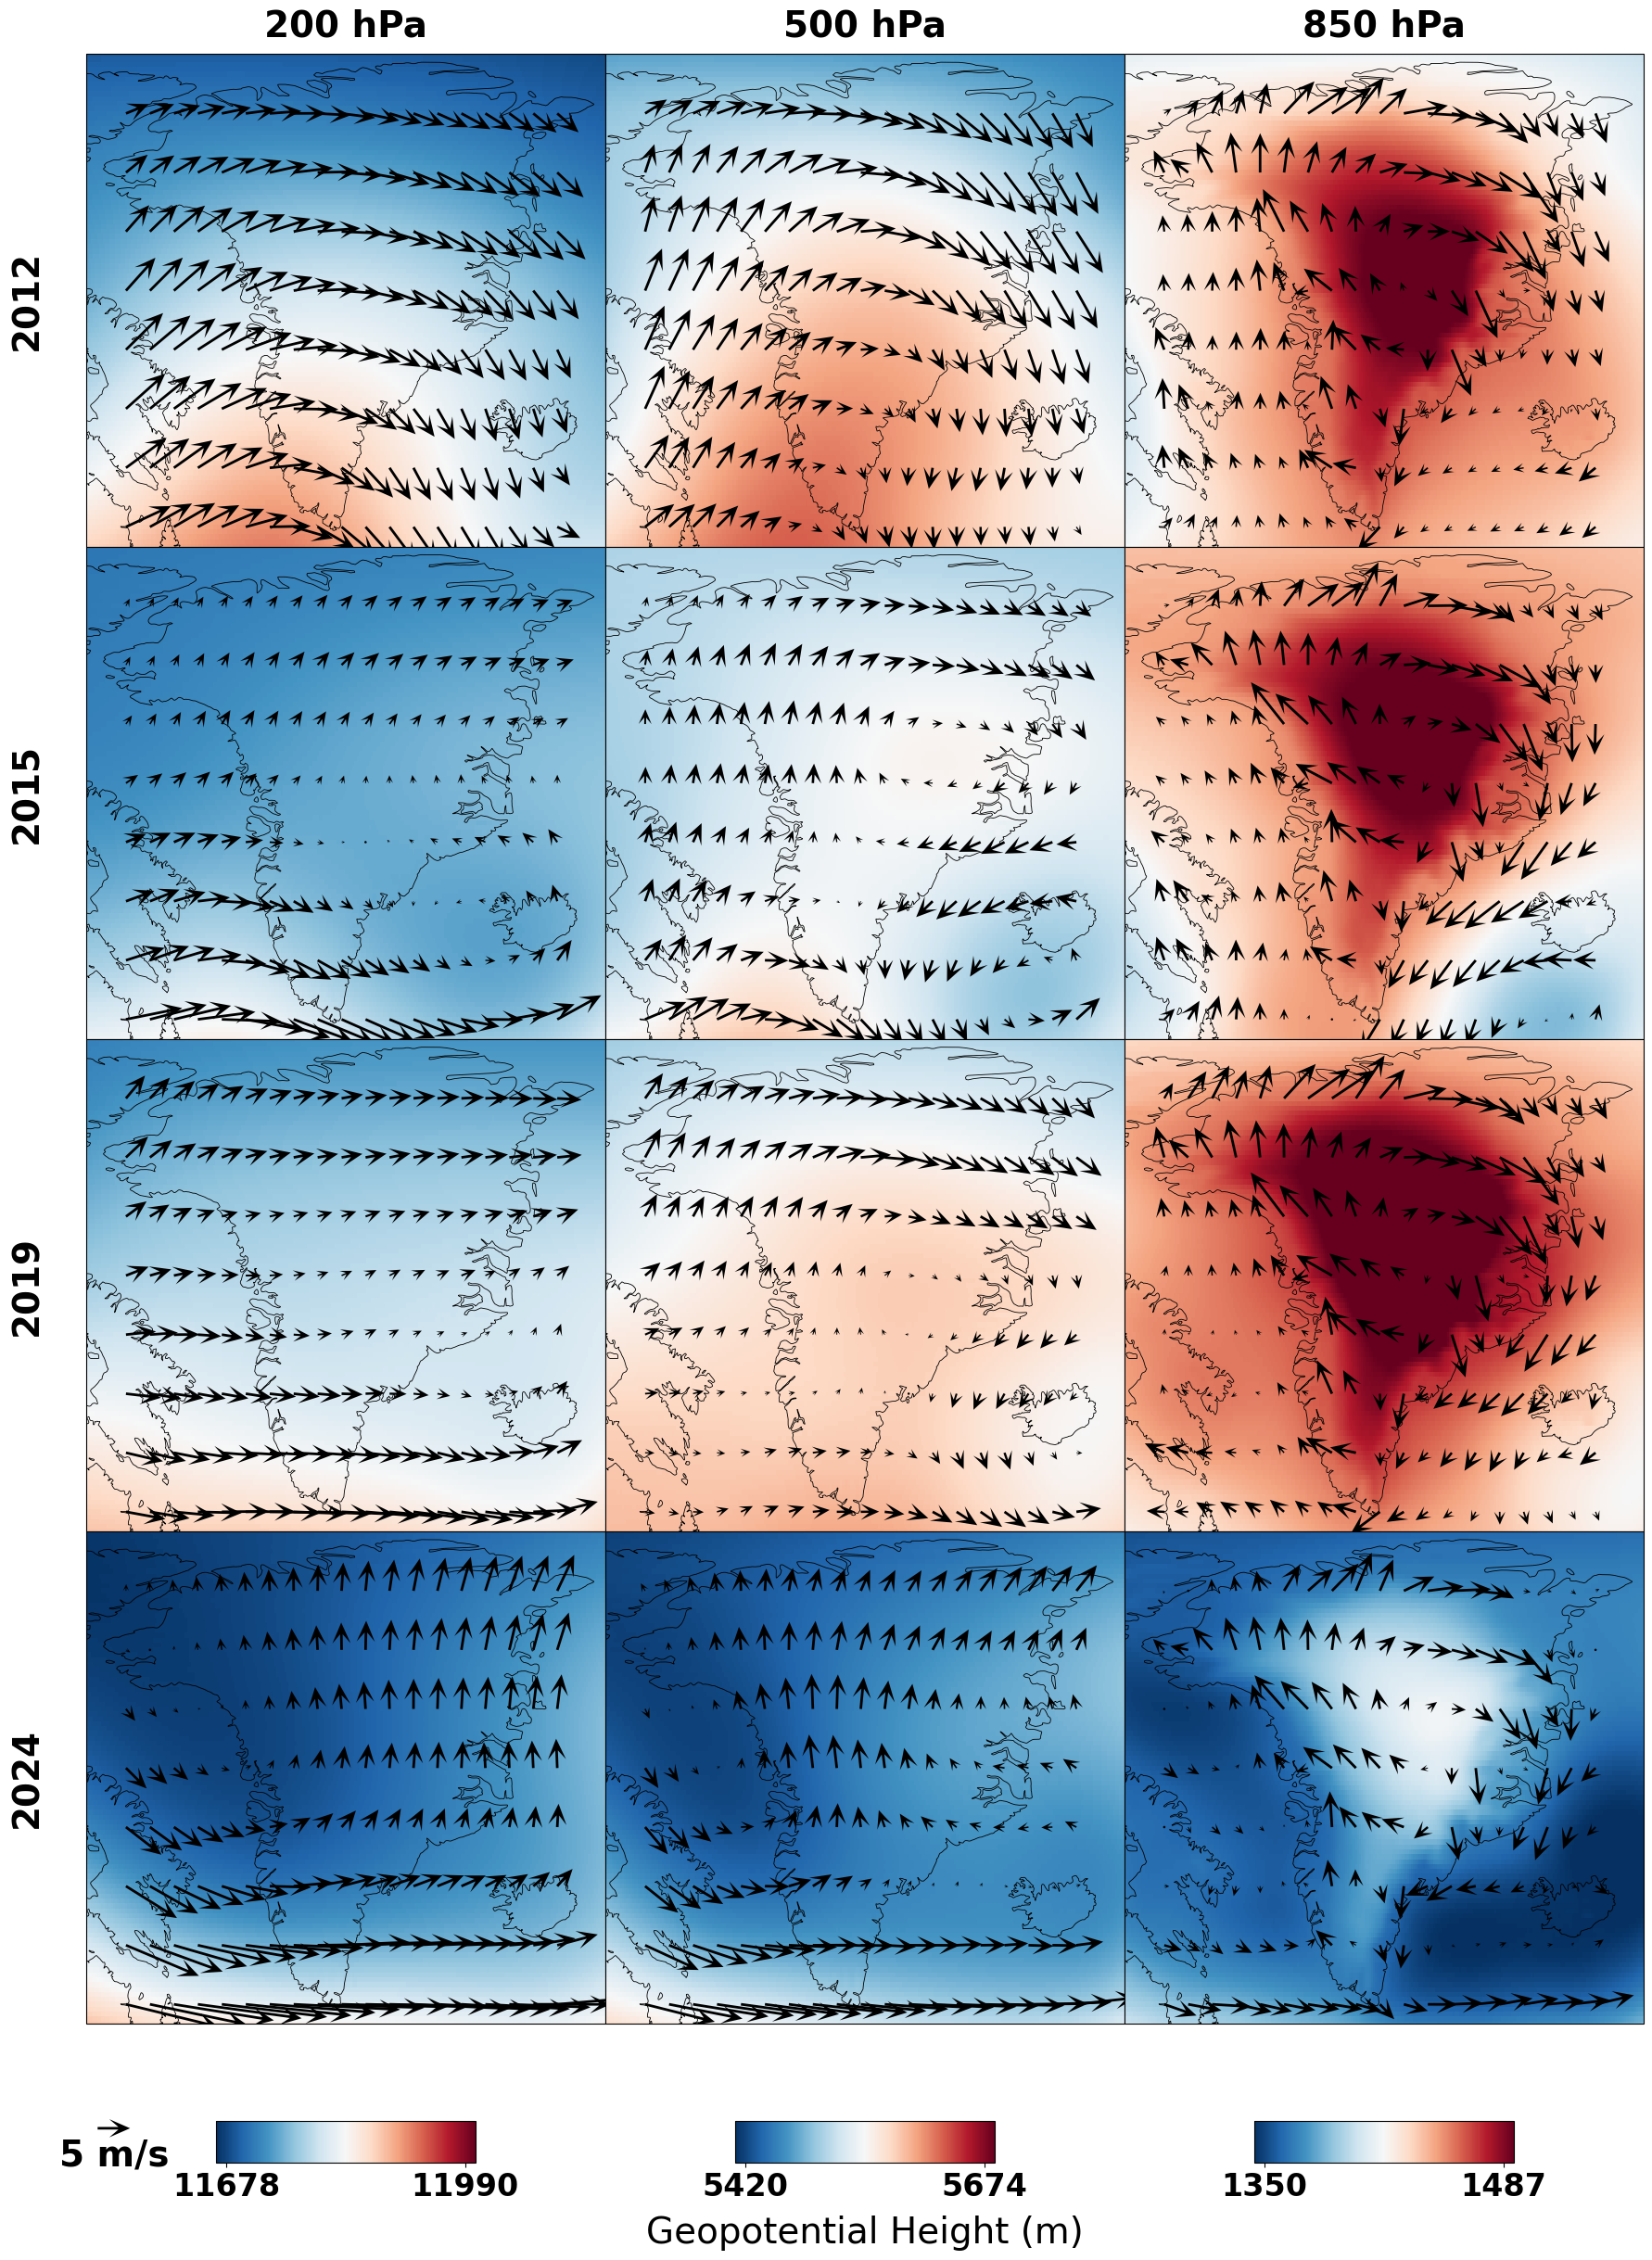

In [17]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===================== 参数 =====================
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"

# 1. 修改年份
YEARS = [2012, 2015, 2019, 2024]
LEVELS = [200, 500, 850]

LON_MIN, LON_MAX = -75, -10
LAT_MIN, LAT_MAX = 59, 83

# 箭头内缩
MARGIN_LON = 5
MARGIN_LAT = 0

arrow_lon_min = LON_MIN + MARGIN_LON
arrow_lon_max = LON_MAX - MARGIN_LON
arrow_lat_min = LAT_MIN + MARGIN_LAT
arrow_lat_max = LAT_MAX - MARGIN_LAT

# 格陵兰区域
GREENLAND_LON_MIN, GREENLAND_LON_MAX = -73, -15
GREENLAND_LAT_MIN, GREENLAND_LAT_MAX = 60, 82

plt.rcParams["font.size"] = 28
plt.rcParams["font.weight"] = "bold"

# ===================== 数据读取 =====================
ds = xr.open_dataset(path)
ds["z"] = ds["z"] / 9.80665

# ========== 加速点 1：提前计算所有 YEAR × LEVEL 平均 ==========
mean_cache = {}

for year in YEARS:
    idx = (ds.valid_time.dt.year == year) & ds.valid_time.dt.month.isin([6, 7, 8])
    ds_year = ds.isel(valid_time=idx).mean("valid_time")  # 一年只算一次

    for lev in LEVELS:
        mean_cache[(year, lev)] = ds_year.sel(pressure_level=lev)

# ========== 提前计算色标范围 ==========
z_vminmax = {}
for lev in LEVELS:
    all_vals = [mean_cache[(y, lev)].z.values for y in YEARS]
    arr = np.concatenate([x.flatten() for x in all_vals])
    z_vminmax[lev] = (np.percentile(arr, 2), np.percentile(arr, 98))

# ===================== 画布 =====================
fig = plt.figure(figsize=(20, 25))
gs = fig.add_gridspec(
    nrows=len(YEARS), ncols=len(LEVELS),
    left=0.03, right=0.87,
    top=0.97, bottom=0.12,
    wspace=0.0, hspace=0.0
)

col_mappable = {}
axes_list = []

# 用于存储最后生成的 quiver 对象以生成图例
last_quiver = None 

# ===================== 正式绘图 =====================
for r, year in enumerate(YEARS):
    for c, lev in enumerate(LEVELS):

        ax = fig.add_subplot(gs[r, c], projection=ccrs.PlateCarree())
        if r == 0 and c == 0:
            axes_list.append(ax)

        ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
        ax.set_aspect("auto")

        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.LAND, facecolor="none", linewidth=0.4)
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

        d = mean_cache[(year, lev)]
        lon, lat = d.longitude, d.latitude
        z = d.z
        u, v = d.u, d.v

        # 背景色
        vmin, vmax = z_vminmax[lev]
        p = ax.pcolormesh(
            lon, lat, z,
            cmap="RdBu_r", shading="nearest",
            vmin=vmin, vmax=vmax,
            rasterized=True
        )
        if r == 0:
            col_mappable[c] = p

        # ========== 加速点 2：箭头筛选向量化 ==========
        step = 12
        lon2d, lat2d = np.meshgrid(lon.values[::step], lat.values[::step])
        u2d = u.values[::step, ::step]
        v2d = v.values[::step, ::step]

        mask = (
            (GREENLAND_LON_MIN <= lon2d) & (lon2d <= GREENLAND_LON_MAX) &
            (GREENLAND_LAT_MIN <= lat2d) & (lat2d <= GREENLAND_LAT_MAX) &
            (arrow_lon_min <= lon2d) & (lon2d <= arrow_lon_max) &
            (arrow_lat_min <= lat2d) & (lat2d <= arrow_lat_max)
        )

        # 这里的 scale=80 是物理基准，图例会自动沿用
        last_quiver = ax.quiver(
            lon2d[mask], lat2d[mask],
            u2d[mask], v2d[mask],
            color="black", scale=80,
            width=0.005, headwidth=7, headlength=8
        )

        # 列标题
        if r == 0:
            ax.text(0.5, 1.02, f"{lev} hPa",
                    transform=ax.transAxes, ha="center", va="bottom")

        # 行标题（去掉 JJA + 旋转）
        if c == 0:
            ax.text(-0.08, 0.5, f"{year}",
                    transform=ax.transAxes,
                    ha="right", va="center",
                    rotation=90)
# ===================== 色标自动对齐每列 =====================
# 色标位置参数
cb_y_pos = 0.06
cb_height = 0.018

for c, lev in enumerate(LEVELS):
    m = col_mappable.get(c)
    if m is None:
        continue

    bbox = gs[:, c].get_position(fig)
    x0, x1 = bbox.x0, bbox.x1

    # === 色标缩短 50% 并保持列中对齐 ===
    col_center = (x0 + x1) / 2
    new_width = (x1 - x0) * 0.50       
    new_x0 = col_center - new_width / 2 

    cax = fig.add_axes([new_x0, cb_y_pos, new_width, cb_height])

    cb = plt.colorbar(m, cax=cax, orientation="horizontal")

    vmin, vmax = z_vminmax[lev]
    offset = (vmax - vmin) * 0.04
    cb.set_ticks([vmin + offset, vmax - offset])
    cb.set_ticklabels([f"{vmin:.0f}", f"{vmax:.0f}"])
    cb.ax.tick_params(labelsize=24)

    if c == 1:
        cb.set_label("Geopotential Height (m)", labelpad=10)

# ===================== 左下角水平 5 m/s 箭头 (严谨修正版) =====================
if last_quiver is not None:
    # 2. 修改数值为 5
    # 3. 严格长度：quiverkey 会自动根据 scale=80 计算 5 m/s 的长度
    # 4. 上移位置：Y=0.075 使得箭头与色标(y=0.06~0.078)基本水平对齐
    plt.quiverkey(
        last_quiver,           
        X=0.045, Y=0.075,      # X位置微调在最左侧，Y位置对齐色标中心
        U=5,                   # 参考值：5 m/s
        label='5 m/s',         # 标签
        labelpos='S',          # 标签在下方
        coordinates='figure',  
        fontproperties={'weight': 'bold', 'size': 28}
    )

plt.show()